In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"

INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input/ceilometer')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
# try:
#     new_dir = pathlib.Path(FIG_DIR)
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

# make data directory to put in ceilometer processed data
OUT_DIR = os.path.join(OUTPUT_DATA_DIR, 'ceilometer/combined')
try:
    new_dir = pathlib.Path(OUT_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

mimi.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, np, plt, cm, BoundaryNorm, LinearSegmentedColormap,fct, datetime, pd, glob)


In [3]:
# reload imports
%load_ext autoreload
%autoreload 2

In [4]:
date_ranges = {
    "2021": pd.date_range("2021-03-16", "2021-03-30").strftime("%Y%m%d").tolist(),
    # "2021": pd.date_range("2021-03-17", "2021-03-18").strftime("%Y%m%d").tolist(),
    "2022": pd.date_range("2022-03-17", "2022-04-07").strftime("%Y%m%d").tolist(),
    "2023": pd.date_range("2023-02-12", "2023-03-14").strftime("%Y%m%d").tolist(),
}

In [5]:
range_cl61  = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'cl61_corrected/*_20230223.nc'))))['altitude']
layer_cl61  = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'cl61_corrected/*_20230223.nc'))))['layer']

range_anx   = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, f'E_PROFILE_corrected/*_A20230222.nc'))))['altitude']
layer_anx   = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, f'E_PROFILE_corrected/*_A20230222.nc'))))['layer']

In [6]:
# create a unified range axis that combines both cl61 and ANX range arrays
# Round to avoid floating point precision mismatches 
range_cl61_rounded = np.round(range_cl61.values, 3)
range_anx_rounded = np.round(range_anx.values, 3)
        
# Create unified sorted range axis
range_combined = np.sort(np.unique(np.concatenate((range_cl61_rounded, range_anx_rounded))))
layer_combined = np.sort(np.unique(np.concatenate((layer_cl61, layer_anx))))



In [7]:


# Looping over date ranges
for key, dates in date_ranges.items():
    for date in dates:  # Limit to first date for now
        path = os.path.join(OUT_DIR,f"bsc_cbh_{date}.nc")
        
        files_cl61 = sorted(glob(os.path.join(INPUT_DATA_DIR, f'cl61_corrected/*_{date}.nc')))
        files_anx = sorted(glob(os.path.join(INPUT_DATA_DIR, f'E_PROFILE_corrected/*_A{date}.nc')))

        ds_cl61 = fct.load_and_insert_backscatter_cbh(
            files=files_cl61,
            var_name_bsc='beta_att',
            var_name_cbh='cloud_base_heights',
            range_rounded=range_cl61_rounded,
            range_combined=range_combined,
            layer_rounded=layer_cl61,
            layer_combined=layer_combined,
            data_vars=['beta_att', 'cloud_base_heights'],
            drop_vars=['lon','lat','elevation','beta_att_sum','beta_att_noise_level','vertical_visibility','p_pol','x_pol','linear_depol_ratio',]
        )
        
        
        ds_anx = fct.load_and_insert_backscatter_cbh(
            files=files_anx,
            var_name_bsc='attenuated_backscatter_0',
            var_name_cbh='cloud_base_height',
            range_rounded=range_anx_rounded,
            range_combined=range_combined,
            layer_rounded=layer_anx,
            layer_combined=layer_combined,
            data_vars = ['attenuated_backscatter_0', 'cloud_base_height'],
            drop_vars = ['start_time', 'latitude', 'longitude', 'uncertainties_att_backscatter_0', 'l0_wavelength', 'station_longitude', 'station_latitude', 'station_altitude', 'quality_flag', 'vertical_visibility', 'cbh_uncertainties', 'cloud_amount', 'calibration_constant_0']
        )

        if ds_cl61 is not None:
            print(f"writing CL61 file: ... {path} ")
            ds_cl61.to_netcdf(path=path)
        if ds_anx is not None:
            print(f"writing ANX file: ... {path} ")
            ds_anx.to_netcdf(path=path)

        if ds_cl61 is None and ds_anx is None:
            print(f"No files found for {date} in {key}")
        


writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210316.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210317.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210318.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210319.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210320.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210321.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210322.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210323.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210324.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210325.nc 
writing ANX file: ... /mn/vann/franzihe/input/ceilometer/combined/bsc_cbh_20210326.nc 
writing ANX file: ... /mn/vann/franzihe/inp

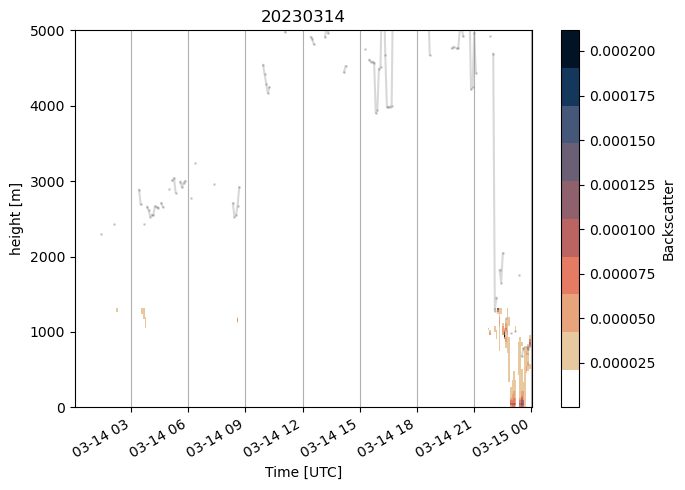

In [8]:
bsc = ds_anx.bsc.dropna(dim=('altitude'))
cbh = ds_anx.cbh.isel(layer = 1).where(ds_anx.cbh.isel(layer = 0) > -1.)


# plot figure
fig, axsm = plt.subplots(1,1, figsize=[7,5],)
cmap = cm.lipari_r  # define the colormap
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# force the first color entry to be white
cmaplist[0] = (255,255,255, 0.9)
# create the new map
cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 10) # cmap.N
# define the bins and normalize
bounds = np.linspace(0, 7e7, 11)
norm = BoundaryNorm(bounds, cmap.N)


# ceilometer backscatter   
(bsc.where(bsc>=0.)).plot.pcolormesh(ax = axsm, x='time', cmap = cmap, #norm = norm, 
                                     cbar_kwargs = {'spacing': 'proportional','label': 'Backscatter'})

#cloud base 
cbh.plot(ax = axsm, x = 'time', marker=".", color = 'grey', alpha=0.3, markersize=2, add_legend=True, label='Cloud Base', )


axsm.set_ylim([0, 5000])
# axsm.set_xlim([datetime.date(str(year), str(month), str(day)), datetime.date(str(year), str(month), str(day+1))])
day_start   = (datetime.datetime.strptime(f"{date} 00:00:00", '%Y%m%d %H:%M:%S').strftime('%Y-%m-%d %H:%M:%S'))
day_end     = (datetime.datetime.strptime(f"{date} 00:00:00", '%Y%m%d %H:%M:%S') + datetime.timedelta(hours=23, minutes=59)).strftime('%Y-%m-%d %H:%M:%S')
xmax = (datetime.datetime.strptime(day_end, '%Y-%m-%d %H:%M:%S') + datetime.timedelta(minutes=1,)).strftime('%Y-%m-%d %H:%M:%S')
# axsm.set_xlim([day_start, xmax])
# Set title and labels for axes
axsm.set(xlabel="Time [UTC]",
ylabel="height [m]",
title=f"{date}")
axsm.xaxis.grid()

# # Define the date format
# date_form = DateFormatter("%H:00")
# axsm.xaxis.set_major_formatter(date_form)

plt.tight_layout();